# Приведение к стационарности

## Подготовка

In [1]:
# Handling data
import pandas as pd
import numpy as np
import requests

# Visualizations
import matplotlib.pyplot as plt
import plotly.express as px

# Stationarity tests
from statsmodels.tsa.stattools import adfuller, kpss

# Autocorr test
from statsmodels.stats.diagnostic import acorr_ljungbox

# Autocorrelation analysis
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ARIMA models
from statsmodels.tsa.arima.model import ARIMA

# Decomposition
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.seasonal import STL, MSTL

In [2]:
!pip install pmdarima

# auto ARIMA
import pmdarima as pm
from pmdarima import auto_arima

In [3]:
def adf_test(timeseries):
    print("Results of Dickey-Fuller Test:")
    dftest = adfuller(timeseries, autolag="AIC", regression="c")
    dfoutput = pd.Series(
        dftest[0:4],
        index=[
            "Test Statistic",
            "p-value",
            "#Lags Used",
            "Number of Observations Used",
        ],
    )
    for key, value in dftest[4].items():
        dfoutput["Critical Value (%s)" % key] = value
    print(dfoutput)

In [4]:
def kpss_test(timeseries):
    print("Results of KPSS Test:")
    kpsstest = kpss(timeseries, regression="c", nlags="auto")
    kpss_output = pd.Series(
        kpsstest[0:3], index=["Test Statistic", "p-value", "Lags Used"]
    )
    for key, value in kpsstest[3].items():
        kpss_output["Critical Value (%s)" % key] = value
    print(kpss_output)

## Данные

Будем анализировать цены закрытия акций Microsoft. Источник — [страница исторических данных Nasdaq](https://www.nasdaq.com/market-activity/stocks/msft/historical).

Следующая ячейка обращается к источнику, который использует эта страница, и загружает данные до 20.09.2026.

In [5]:
end_date = pd.Timestamp('2026-09-20')
url = f"https://api.nasdaq.com/api/quote/MSFT/historical?assetclass=stocks&fromdate={end_date - pd.DateOffset(years=5):%Y-%m-%d}&todate={end_date:%Y-%m-%d}&limit=5000"
stocks = pd.DataFrame(requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).json()["data"]["tradesTable"]["rows"])

In [6]:
stocks.head()

,date,close,volume,open,high,low
0,09/18/2026,$493.78,"39,622,290",$497.965,$498.65,$491.10
1,09/17/2026,$497.75,"17,841,640",$497.795,$501.47,$493.17
2,09/16/2026,$490.30,"16,670,290",$493.03,$495.97,$487.23
3,09/15/2026,$497.12,"17,794,610",$500.06,$505.90,$495.54
4,09/14/2026,$505.41,"23,091,890",$497.06,$509.95,$495.3416


Немного предобработки.

In [7]:
stocks_raw = stocks.copy()  # исходные данные понадобятся нам позже
stocks = stocks.rename(columns={'date': 'ds', 'close': 'y'})
stocks['ds'] = pd.to_datetime(stocks['ds'], format='%m/%d/%Y')
stocks['y'] = stocks['y'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

stocks = stocks[['ds', 'y']].sort_values('ds').set_index('ds')

In [8]:
stocks.head()

,y
ds,
2021-09-20,294.30
2021-09-21,294.80
2021-09-22,298.58
2021-09-23,299.56
2021-09-24,299.35


Построим график данных.

In [9]:
fig = px.line(stocks, x=stocks.index, y=stocks['y'],
              title="Microsoft closing prices (daily)")

fig.update_layout(template='plotly_white', width=800, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

На занятиях 3–4 мы обсуждали модели **ARMA**, которые работают только со **стационарными** временными рядами.

Понимание и применение методов приведения к стационарности критически важны при анализе временных рядов: они переводят данные в формат, который соответствует предпосылкам многих статистических и ML-моделей, что делает выводы точнее и понятнее.

## Дифференцирование

Дифференцирование — один из способов привести ряд к стационарности. Оно особенно полезно для устранения стохастического тренда. Обычная разность — это вычитание предыдущего значения из текущего; сезонная разность использует значение через сезонный лаг.

Дифференцирование не гарантирует стационарность: меняющаяся дисперсия или структурные сдвиги могут сохраниться. Для детерминированного тренда можно также рассмотреть его явное моделирование или удаление.

Порядок дифференцирования показывает, сколько раз применена операция. Часто достаточно первого порядка.

**Формула** (1-й порядок)

$\Delta y_t = y_t-y_{t-1}$.

In [10]:
stocks['diff'] = stocks['y'].diff()
stocks.head()

,y,diff
ds,,
2021-09-20,294.30,NaN
2021-09-21,294.80,0.50
2021-09-22,298.58,3.78
2021-09-23,299.56,0.98
2021-09-24,299.35,-0.21


Посмотрим, сделало ли дифференцирование первого порядка наш ряд стационарным.

In [11]:
fig = px.line(stocks, x=stocks.index, y=stocks['diff'],
              title="Microsoft closing prices (daily) - diff(1))")

fig.update_layout(template='plotly_white', width=800, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

После дифференцирования выраженный рост уровня исчез. Проверим с помощью тестов ADF и KPSS.

In [12]:
adf_test(stocks['diff'].dropna())

Results of Dickey-Fuller Test:
Test Statistic                  -34.627088
p-value                           0.000000
#Lags Used                        0.000000
Number of Observations Used    1253.000000
Critical Value (1%)              -3.435580
Critical Value (5%)              -2.863849
Critical Value (10%)             -2.568000
dtype: float64


/tmp/ipykernel_22950/4074047635.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



In [13]:
kpss_test(stocks['diff'].dropna())

Results of KPSS Test:
Test Statistic           0.055106
p-value                  0.100000
Lags Used                2.000000
Critical Value (10%)     0.347000
Critical Value (5%)      0.463000
Critical Value (2.5%)    0.574000
Critical Value (1%)      0.739000
dtype: float64


/tmp/ipykernel_22950/11026176.py:3: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_22950/11026176.py:3: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



По ADF и KPSS тестам ряд стационарен.

Но как вернуть исходные значения? Один из способов — использовать `cumsum`.

In [14]:
stocks

,y,diff
ds,,
2021-09-20,294.30,NaN
2021-09-21,294.80,0.50
2021-09-22,298.58,3.78
2021-09-23,299.56,0.98
2021-09-24,299.35,-0.21
...,...,...
2026-09-14,505.41,9.78
2026-09-15,497.12,-8.29
2026-09-16,490.30,-6.82


In [15]:
y_0 = stocks['y'].iloc[0] # берем первое значение как отправную точку
stocks['y_restored_diff'] = np.cumsum(stocks['diff'])+y_0
stocks

,y,diff,y_restored_diff
ds,,,
2021-09-20,294.30,NaN,NaN
2021-09-21,294.80,0.50,294.80
2021-09-22,298.58,3.78,298.58
2021-09-23,299.56,0.98,299.56
2021-09-24,299.35,-0.21,299.35
...,...,...,...
2026-09-14,505.41,9.78,505.41
2026-09-15,497.12,-8.29,497.12
2026-09-16,490.30,-6.82,490.30


Теперь построим восстановленные значения и убедимся, что они совпадают с исходными.

In [16]:
fig = px.line(title="Microsoft closing prices (daily) - diff(1)")
fig.add_scatter(x=stocks.index, y=stocks['y'], mode='lines', name='original y', line=dict(color='silver'))
fig.add_scatter(x=stocks.index, y=stocks['y_restored_diff'], mode='lines', name='restored y', line=dict(color='red'))

fig.update_layout(template='plotly_white', width=1000, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Иногда дифференцированный ряд всё ещё выглядит нестационарным, и тогда приходится применять дифференцирование второго порядка. На практике почти никогда не нужно идти дальше второго порядка.

В нашем примере второго порядка не требуется, но ниже показано, как его выполнить при необходимости.



In [17]:
stocks['y'].diff().diff()

,y
ds,
2021-09-20,NaN
2021-09-21,NaN
2021-09-22,3.28
2021-09-23,-2.80
2021-09-24,-1.19
...,...
2026-09-14,6.59
2026-09-15,-18.07
2026-09-16,1.47


## Процентный прирост (percent change)

Процентный прирост очень похож на показатели MoM и YoY, о которых мы говорили на уроках 1–2.

**Формула**

pct\_change$_t = \frac{Y_t - Y_{t-1}}{Y_{t-1}} \times 100$

In [18]:
stocks['pct_change'] = stocks['y'].pct_change()*100
stocks.head()

,y,diff,y_restored_diff,pct_change
ds,,,,
2021-09-20,294.30,NaN,NaN,NaN
2021-09-21,294.80,0.50,294.80,0.169895
2021-09-22,298.58,3.78,298.58,1.282225
2021-09-23,299.56,0.98,299.56,0.328220
2021-09-24,299.35,-0.21,299.35,-0.070103


Посмотрим, сделало ли преобразование через процентный прирост наш ряд стационарным.

In [19]:
fig = px.line(stocks, x=stocks.index, y=stocks['pct_change'],
              title="Microsoft closing prices (daily) - pct_change")

fig.update_layout(template='plotly_white', width=800, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Также проверим это с помощью ADF-теста.

In [20]:
adf_test(stocks['pct_change'].dropna())

Results of Dickey-Fuller Test:
Test Statistic                  -34.892838
p-value                           0.000000
#Lags Used                        0.000000
Number of Observations Used    1253.000000
Critical Value (1%)              -3.435580
Critical Value (5%)              -2.863849
Critical Value (10%)             -2.568000
dtype: float64


/tmp/ipykernel_22950/4074047635.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



In [21]:
kpss_test(stocks['pct_change'].dropna())

Results of KPSS Test:
Test Statistic           0.053834
p-value                  0.100000
Lags Used                5.000000
Critical Value (10%)     0.347000
Critical Value (5%)      0.463000
Critical Value (2.5%)    0.574000
Critical Value (1%)      0.739000
dtype: float64


/tmp/ipykernel_22950/11026176.py:3: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_22950/11026176.py:3: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



По ADF и KPSS тестам ряд стационарен.

Как восстановить исходный ряд?

In [22]:
y_0 = stocks['y'].iloc[0]
stocks['y_restored_pct_change'] = stocks['y'].shift(1)*(1 + stocks['pct_change'] / 100)
stocks

,y,diff,y_restored_diff,pct_change,y_restored_pct_change
ds,,,,,
2021-09-20,294.30,NaN,NaN,NaN,NaN
2021-09-21,294.80,0.50,294.80,0.169895,294.80
2021-09-22,298.58,3.78,298.58,1.282225,298.58
2021-09-23,299.56,0.98,299.56,0.328220,299.56
2021-09-24,299.35,-0.21,299.35,-0.070103,299.35
...,...,...,...,...,...
2026-09-14,505.41,9.78,505.41,1.973246,505.41
2026-09-15,497.12,-8.29,497.12,-1.640252,497.12
2026-09-16,490.30,-6.82,490.30,-1.371902,490.30


In [23]:
fig = px.line(title="Microsoft closing prices (daily) - pct_change")
fig.add_scatter(x=stocks.index, y=stocks['y'], mode='lines', name='original y', line=dict(color='silver'))
fig.add_scatter(x=stocks.index, y=stocks['y_restored_pct_change'], mode='lines', name='restored y', line=dict(color='green'))

fig.update_layout(template='plotly_white', width=1000, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

При анализе цен акций удобно переходить от абсолютных изменений к относительным: делить изменение на цену предыдущего периода. Так получаем ценовую доходность; при умножении на 100 она выражается в процентах. Здесь дивиденды не учитываются.

Относительные изменения удобнее сравнивать между активами и периодами с разными уровнями цен. Например, рост на 10 долларов при цене 100 долларов и при цене 1000 долларов — это 10% и 1% соответственно. Но доходности не становятся автоматически стационарными: у них могут сохраняться выбросы, тяжёлые хвосты и меняющаяся волатильность.

## Декомпозиция

Декомпозиция временного ряда — это разложение ряда на компоненты. Цель — лучше понять структуру данных, которая обычно включает:

* **Тренд**: долгосрочное направление движения ряда.
* **Сезонность**: повторяющиеся паттерны или циклы на регулярных интервалах.
* **Остаточная компонента или остатки**: всё, что остаётся после удаления тренда и сезонности. Она может содержать как случайные колебания, так и зависимость, которую ещё можно моделировать.

Такой подход помогает осмысленно анализировать временные ряды и находить проблемы при анализе и прогнозировании. Тренд и сезонность могут присутствовать или отсутствовать; остаточная компонента не обязательно является белым шумом. Компоненты можно рассматривать как аддитивные или мультипликативные.

* **Аддитивная модель**:

  $y(t) = Trend + Seasonality + Residuals$

* **Мультипликативная модель**:

  $y(t) = Trend * Seasonality * Residuals$

Обратите внимание: остатки могут также называться «remainder».

### Классическая декомпозиция

*Алгоритм аддитивной декомпозиции*

* С помощью центрированного скользящего среднего оцениваем трендово-циклическую компоненту.
* Вычитаем её и усредняем детрендированные значения для каждой позиции внутри сезонного периода.
* Центрируем сезонные значения вокруг нуля и повторяем полученный рисунок для всех периодов.
* Вычитаем тренд и сезонность из исходного ряда — получаем остаточную компоненту.


**Посмотрим на алгоритм в движении.**

Для наглядности возьмём **искусственный ряд ежедневных заказов за 8 недель** с недельным циклом (`period=7`).

🌵 **Почему на краях нет оценки тренда? Почему сезонный рисунок повторяется без изменений?**

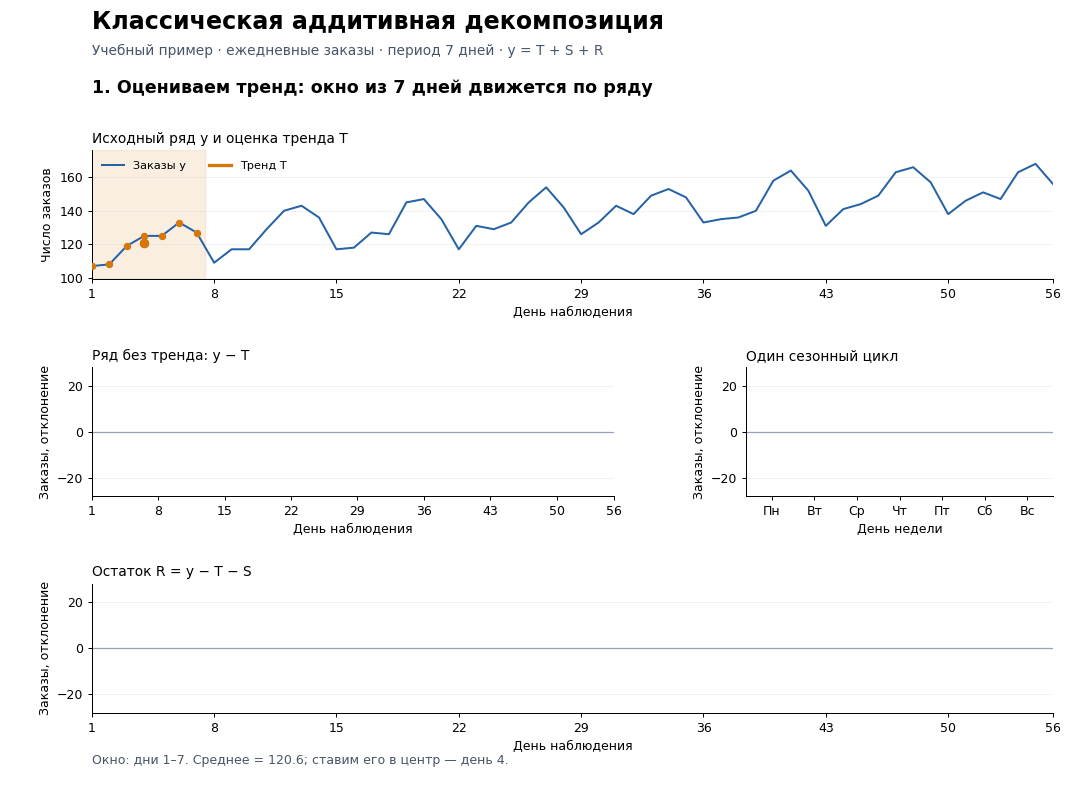

In [24]:
def show_classical_decomposition():
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.animation import FuncAnimation, PillowWriter
    from IPython.display import Image, display

    # Учебный ряд: 8 недель ежедневных заказов, начиная с понедельника.
    rng = np.random.default_rng(42)
    day = np.arange(56)
    weekday = day % 7
    names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
    pattern = np.array([-14, -8, -5, -1, 10, 15, 3])
    orders = np.round(120 + 0.65 * day + pattern[weekday] + rng.normal(0, 4, len(day)))

    # Компоненты оцениваем по ряду, а не берём из формулы генерации.
    trend = pd.Series(orders).rolling(7, center=True).mean().to_numpy()
    detrended = orders - trend
    weekday_means = np.array([np.nanmean(detrended[weekday == d]) for d in range(7)])
    seasonal_pattern = weekday_means - weekday_means.mean()
    seasonal = seasonal_pattern[weekday]
    residual = orders - trend - seasonal
    valid = np.flatnonzero(np.isfinite(trend))

    # По шагам: тренд → детрендирование → средние → центрирование → повтор → остаток.
    frames = []
    for stage, progress in [
        (0, np.linspace(0, len(valid) - 1, 26)),
        (1, np.linspace(0, 1, 16)),
        (2, np.repeat(np.arange(7), 5)),
        (3, np.linspace(0, 1, 14)),
        (4, np.linspace(0, 1, 20)),
        (5, np.linspace(0, 1, 16)),
    ]:
        frames.extend((stage, float(p)) for p in progress)
        frames.extend([(stage, float(progress[-1]))] * (22 if stage == 5 else 7))

    titles = [
        '1. Оцениваем тренд: окно из 7 дней движется по ряду',
        '2. Вычитаем тренд: остаются сезонность и случайные колебания',
        '3. Усредняем значения отдельно для каждого дня недели',
        '4. Центрируем 7 средних: их среднее должно стать нулём',
        '5. Повторяем полученный сезонный рисунок каждую неделю',
        '6. Вычитаем тренд и сезонность: получаем остаток',
    ]
    blue, orange, purple, green = '#2563a6', '#d97706', '#8055ad', '#18836b'

    with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10}):
        fig = plt.figure(figsize=(12, 8.8), facecolor='white')
        grid = fig.add_gridspec(3, 2, width_ratios=[1.7, 1])
        axes = [fig.add_subplot(grid[0, :]), fig.add_subplot(grid[1, 0]),
                fig.add_subplot(grid[1, 1]), fig.add_subplot(grid[2, :])]
        fig.subplots_adjust(left=0.085, right=0.975, bottom=0.10, top=0.81,
                            hspace=0.68, wspace=0.32)
        fig.text(0.085, 0.965, 'Классическая аддитивная декомпозиция', size=19, weight='bold')
        fig.text(0.085, 0.93, 'Учебный пример · ежедневные заказы · период 7 дней · y = T + S + R',
                 size=11, color='#475569')
        heading = fig.text(0.085, 0.882, '', size=14, weight='bold')
        footer = fig.text(0.085, 0.035, '', size=10, color='#475569')

        def draw(frame):
            stage, progress = frame
            top, middle, week, bottom = axes
            for ax in axes:
                ax.clear()
                ax.set_facecolor('white')
                ax.grid(axis='y', alpha=0.16)
                ax.spines[['top', 'right']].set_visible(False)
            for ax in (top, middle, bottom):
                ax.set_xlim(1, len(day))
                ax.set_xticks([1, 8, 15, 22, 29, 36, 43, 50, 56])
                ax.set_xlabel('День наблюдения')
            top.set_ylim(orders.min() - 8, orders.max() + 8)
            middle.set_ylim(-28, 28)
            week.set_ylim(-28, 28)
            bottom.set_ylim(-28, 28)
            for ax in (middle, week, bottom):
                ax.axhline(0, color='#94a3b8', lw=1)
                ax.set_ylabel('Заказы, отклонение')
            top.set_ylabel('Число заказов')
            week.set_xlim(-0.6, 6.6)
            week.set_xticks(range(7), names)
            week.set_xlabel('День недели')
            top.set_title('Исходный ряд y и оценка тренда T', loc='left', size=11)
            middle.set_title('Ряд без тренда: y − T', loc='left', size=11)
            week.set_title('Один сезонный цикл', loc='left', size=11)
            bottom.set_title('Остаток R = y − T − S', loc='left', size=11)
            heading.set_text(titles[stage])
            top.plot(day + 1, orders, color=blue, lw=1.6, label='Заказы y')

            if stage == 0:
                j = int(progress)
                center = valid[j]
                top.axvspan(center - 2.5, center + 4.5, color=orange, alpha=0.12)
                top.scatter(day[center-3:center+4] + 1, orders[center-3:center+4],
                            s=24, color=orange, zorder=3)
                top.plot(valid[:j+1] + 1, trend[valid[:j+1]], color=orange, lw=2.6, label='Тренд T')
                top.scatter([center + 1], [trend[center]], s=45, color=orange, zorder=4)
                footer.set_text(f'Окно: дни {center-2}–{center+4}. Среднее = {trend[center]:.1f}; ставим его в центр — день {center+1}.')
            else:
                top.plot(day + 1, trend, color=orange, lw=2.6, label='Тренд T')
                count = max(1, int(progress * len(valid))) if stage == 1 else len(valid)
                use = valid[:count]
                middle.plot(use + 1, detrended[use], color=blue, marker='.', ms=4, lw=1.1)
                footer.set_text('На первых и последних 3 днях нет полного центрированного окна: тренд и остаток там не оцениваем.')
            top.legend(loc='upper left', ncol=2, fontsize=9, frameon=False)

            if stage >= 2:
                last = int(progress) if stage == 2 else 6
                for d in range(last + 1):
                    values = detrended[(weekday == d) & np.isfinite(detrended)]
                    jitter = np.linspace(-0.14, 0.14, len(values))
                    if stage < 3:
                        week.scatter(d + jitter, values, color=blue, alpha=0.35, s=20)
                    adjustment = progress if stage == 3 else (1 if stage > 3 else 0)
                    average = weekday_means[d] - adjustment * weekday_means.mean()
                    week.plot([d-0.25, d+0.25], [average, average], color=purple, lw=3)
                if stage == 2:
                    mask = (weekday == last) & np.isfinite(detrended)
                    middle.scatter(day[mask] + 1, detrended[mask], color=purple, s=45, zorder=4)
                    footer.set_text(f'{names[last]}: выделяем этот день во всех неделях. Точки справа — его значения y − T; черта — среднее.')
                elif stage == 3:
                    average = weekday_means.mean() * (1 - progress)
                    footer.set_text(f'Из каждого из 7 средних вычитаем одно и то же число: {weekday_means.mean():.2f}. Среднее рисунка сейчас: {average:.2f}.')

            if stage >= 4:
                count = max(1, int(progress * len(day))) if stage == 4 else len(day)
                middle.plot(day[:count] + 1, seasonal[:count], color=purple, lw=2.2, label='Сезонность S')
                middle.legend(loc='upper left', fontsize=9, frameon=False)
                if stage == 4:
                    footer.set_text('Сезонность одинакова во всех неделях: это одна из особенностей классической декомпозиции.')
            if stage == 5:
                count = max(1, int(progress * len(valid)))
                use = valid[:count]
                bottom.plot(use + 1, residual[use], color=green, marker='.', ms=4, lw=1.4)
                footer.set_text('Где оценены все компоненты, y = T + S + R. Остаток — не обязательно белый шум; его свойства проверяем отдельно.')
            return axes

        animation = FuncAnimation(fig, draw, frames=frames, interval=125, blit=False, repeat=True)
        filename = 'classical_decomposition.gif'
        animation.save(filename, writer=PillowWriter(fps=4), dpi=90)
        plt.close(fig)
        display(Image(filename=filename, width=1000))


show_classical_decomposition()


В **мультипликативной декомпозиции** вычитание заменяется делением, а сезонные индексы нормируются так, чтобы их среднее равнялось 1. Для неё нужны положительные значения ряда.


*Ограничения*

* Одна сезонность с фиксированным периодом и неизменным сезонным рисунком.
* Чувствительность к выбросам.
* Резкие изменения тренда могут чрезмерно сглаживаться.
* При стандартном центрированном сглаживании на краях ряда не хватает наблюдений для оценки тренда и остатков.

*Подходит для*

* Простых и устойчивых сезонных паттернов.
* Плавного тренда, который не обязан быть линейным.
* Первичного знакомства со структурой ряда при достаточном числе сезонных циклов.

См. также [Hyndman](https://otexts.com/fpp3/classical-decomposition.html).

Попробуем декомпозицию с разными **периодами**. Период задаётся в числе наблюдений, а у нас наблюдения идут по торговым сессиям.

Для иллюстрации возьмём 5, 20 и 252 сессии — приблизительные аналоги недели, месяца и года. Из-за праздников и неодинаковой длины месяцев это не точные календарные циклы. Само наличие календаря не доказывает сезонность цен акций: здесь мы исследуем результат выбранного разложения.

Те же периоды используем в STL, чтобы не смешивать смену метода и смену периода. Для наглядного бизнес-примера MSTL можно взять почасовые заказы с суточным и недельным циклами — 24 и 168 наблюдений.

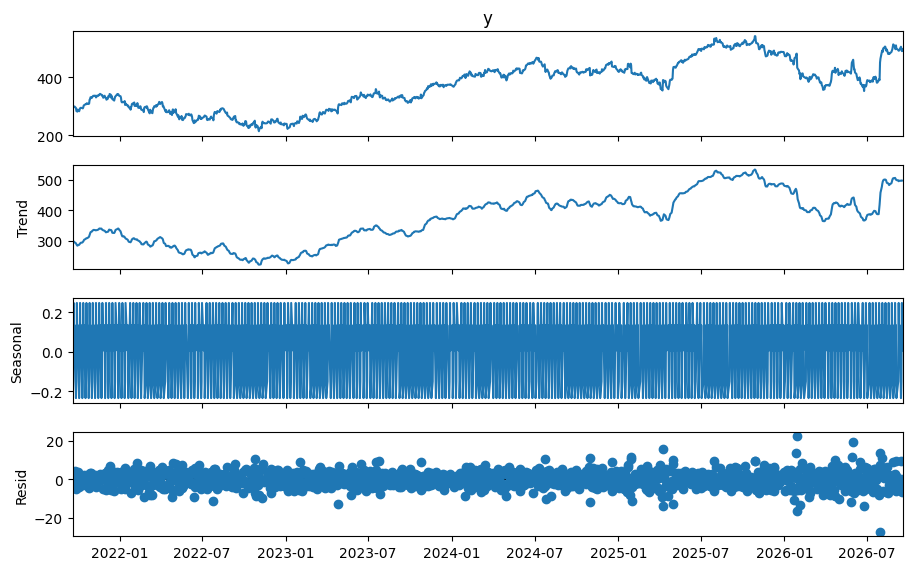

<Axes: xlabel='ds'>

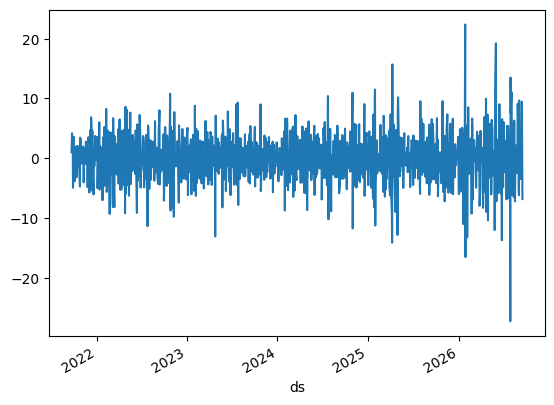

In [27]:
res = seasonal_decompose(stocks['y'],  period=5)

fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

res.resid.plot()

<Axes: xlabel='ds'>

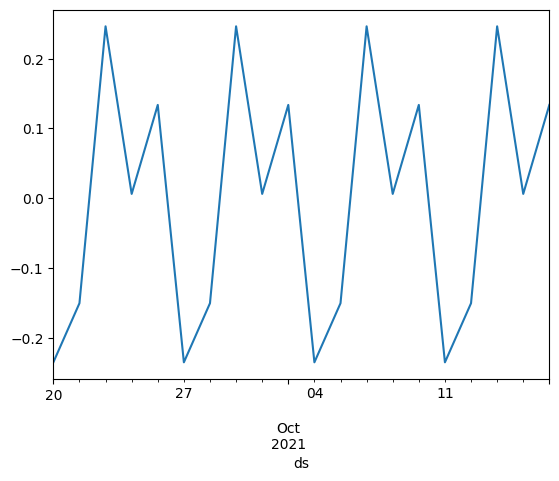

In [28]:
res.seasonal[:5*4].plot()

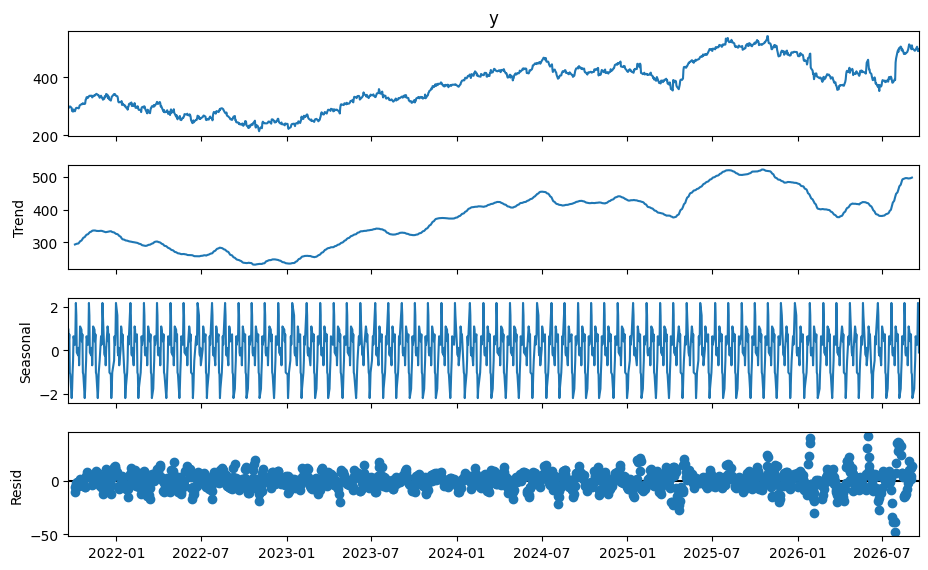

<Axes: xlabel='ds'>

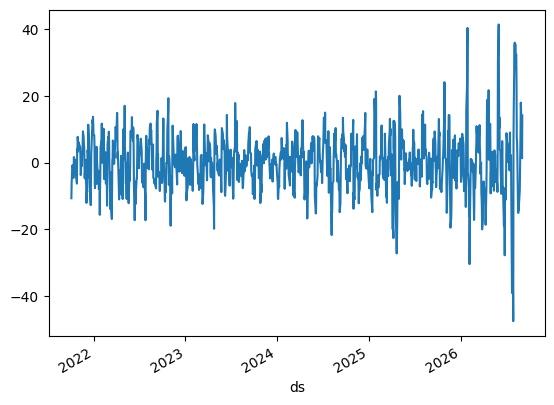

In [29]:
stl = seasonal_decompose(stocks['y'],  period=20)

fig = stl.plot()
fig.set_size_inches(10, 6)
plt.show()

stl.resid.plot()

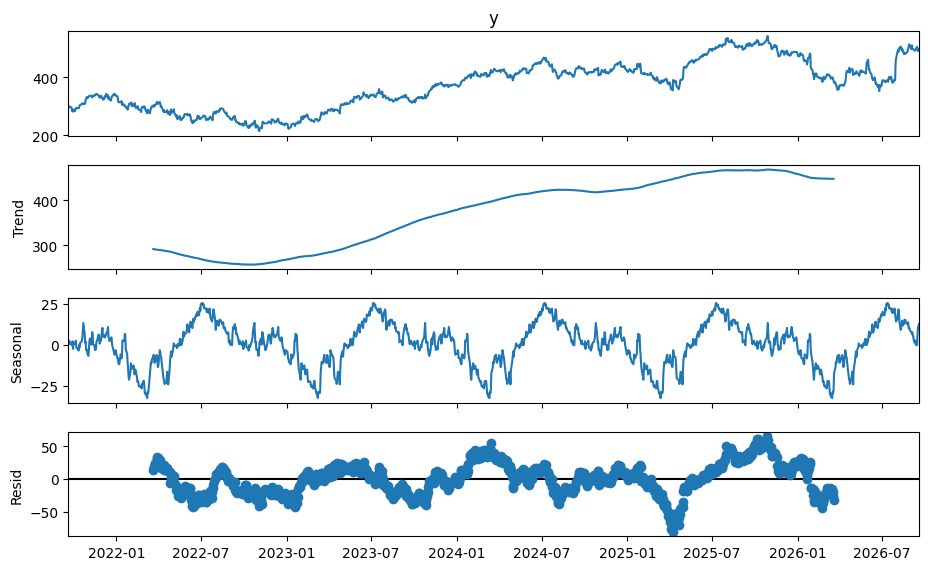

<Axes: xlabel='ds'>

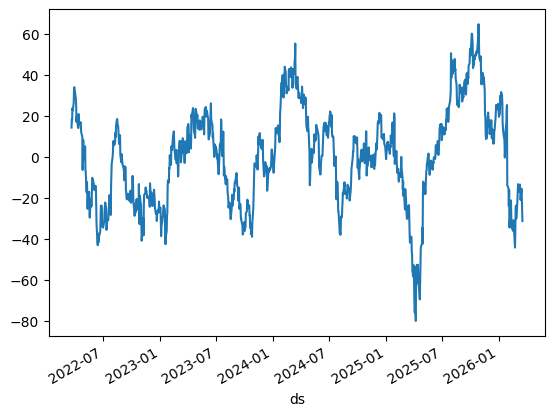

In [30]:
stl = seasonal_decompose(stocks['y'],  period=252)

fig = stl.plot()
fig.set_size_inches(10, 6)
plt.show()

stl.resid.plot()

#### Остатки после декомпозиции

Каждый раз остатки выводились отдельным графиком. Зачем?

По ним видно, какая структура осталась после выделения тренда и сезонности. Остаточная компонента декомпозиции может быть автокоррелированной: эту динамику можно описать отдельной моделью.

🌵 **Что такое белый шум?**

Белый шум имеет нулевое среднее, постоянную конечную дисперсию и нулевую автокорреляцию на ненулевых лагах. В этом смысле он слабо стационарен.

Отсутствие автокорреляции не означает независимости: могут сохраняться нелинейные зависимости, например между квадратами значений.

У конечной прогнозной модели **желательно получить остатки со средним около нуля и без заметной автокорреляции.** После одной лишь декомпозиции автокорреляция допустима: оставшаяся динамика может стать объектом следующей модели.

Итак, **что проверяем в остатках после декомпозиции?**

* **Автокорреляцию.** Она показывает, осталась ли линейная зависимость на рассматриваемых лагах. Она может отражать как неучтённую сезонность, так и обычную краткосрочную динамику.
* **Стационарность.** Она важна для выбора следующей модели: например, стационарную остаточную компоненту можно моделировать ARMA.

**ИТОГ:** стационарность и отсутствие автокорреляции — разные свойства. Ни одно из них само по себе не доказывает, что тренд и сезонность выделены единственным правильным способом. Декомпозиция не обязана сразу давать белый шум.

Проверим автокорреляцию и стационарность остаточной компоненты, чтобы понять, какую структуру ещё предстоит моделировать.

🌵 **Как проверить отсутствие автокорреляции?**

С помощью ACF и PACF:

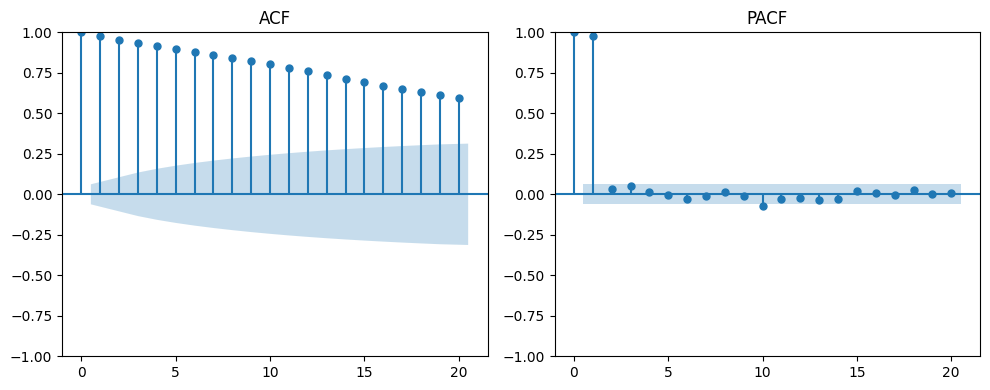

In [31]:
# Остатки последней классической декомпозиции с period=252
# Убираем пропуски на краях и используем один ряд во всех проверках
classical_resid = stl.resid.dropna()

# 2 graphs side by side
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# ACF
plot_acf(classical_resid, ax=ax[0], lags=20)
ax[0].set_title('ACF')

# PACF
plot_pacf(classical_resid, ax=ax[1], lags=20)
ax[1].set_title('PACF')


plt.tight_layout()
plt.show()

С помощью теста Ljung-Box:

In [32]:
acorr_ljungbox(classical_resid, return_df=True)

,lb_stat,lb_pvalue
1,957.812403,2.657828e-210
2,1873.492511,0.000000e+00
3,2753.575696,0.000000e+00
4,3600.432061,0.000000e+00
5,4414.838549,0.000000e+00
6,5195.723635,0.000000e+00
7,5943.653654,0.000000e+00
8,6661.348794,0.000000e+00
9,7349.065259,0.000000e+00
10,8002.532155,0.000000e+00


🌵 **Что скажете про автокорреляцию?**

Если остатки автокоррелированы, в них осталась линейная динамика. Это не обязательно ошибка декомпозиции: такую динамику можно описать отдельной моделью.

🌵 **Как проверить стационарность?**

С помощью ADF-теста:

In [33]:
adf_test(classical_resid)

Results of Dickey-Fuller Test:
Test Statistic                   -3.326115
p-value                           0.013751
#Lags Used                        0.000000
Number of Observations Used    1002.000000
Critical Value (1%)              -3.436893
Critical Value (5%)              -2.864429
Critical Value (10%)             -2.568308
dtype: float64


/tmp/ipykernel_22950/4074047635.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



Подведём итог по остаткам классической декомпозиции с периодом 252.

🌵 **Что показали ADF и проверка автокорреляции при вашем запуске?**

Остатки получились **стационарными, но автокоррелированными**. Их оставшуюся динамику можно попробовать описать моделью ARMA.

### Декомпозиция STL

**STL** (Seasonal and Trend decomposition using LOESS) использует локально взвешенную регрессию для оценки тренда и одной сезонной компоненты. В отличие от классической декомпозиции, сезонный рисунок может плавно меняться во времени.

*Алгоритм*

* Во внутреннем цикле оцениваются и уточняются сезонность и тренд с помощью сглаживания LOESS. При локальном сглаживании ближайшие точки получают больший вес.
* В робастном варианте внешний цикл дополнительно уменьшает влияние наблюдений с большими остатками. Это другие веса: они зависят от величины остатка, а не от расстояния во времени.
* Основные настройки — период сезонности и окна сглаживания сезонности и тренда.

*Ограничения*

* Устойчивость к выбросам включается через `robust=True`; по умолчанию в statsmodels она выключена. Ниже используем робастный вариант.
* Праздники и другие календарные события автоматически не учитываются.
* STL даёт аддитивное разложение. Для положительных данных с мультипликативной структурой можно сначала взять логарифм, а затем выполнить обратное преобразование компонент.

*Подходит для*

* Одной сезонности с постепенно меняющимся рисунком.
* Плавных линейных или нелинейных трендов.
* Данных с выбросами, если используется робастный вариант.

См. также [Hyndman](https://otexts.com/fpp3/stl.html) и [Демешева](https://www.youtube.com/watch?v=bTmsWGNCLfI).

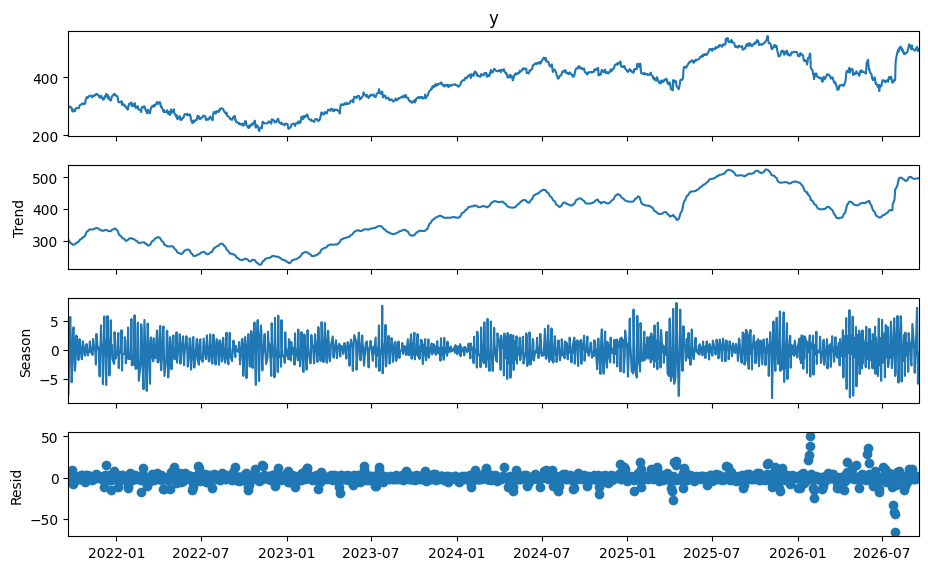

<Axes: xlabel='ds'>

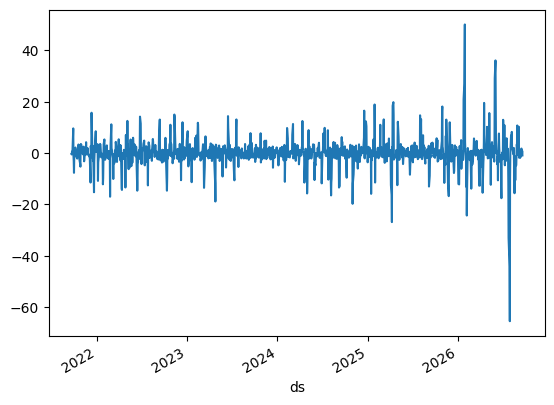

In [34]:
stl = STL(stocks['y'],  period=5, robust=True)
res = stl.fit()

fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

res.resid.plot()

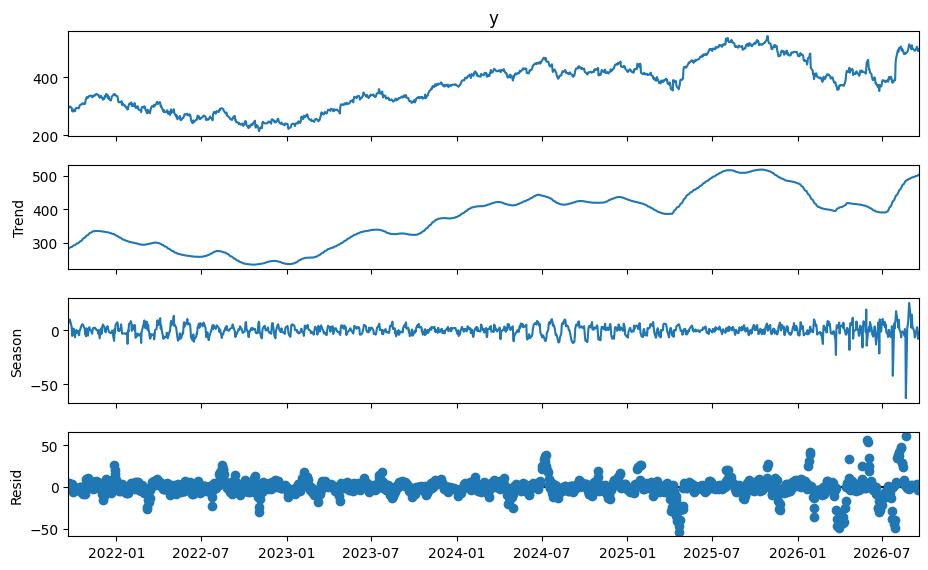

<Axes: xlabel='ds'>

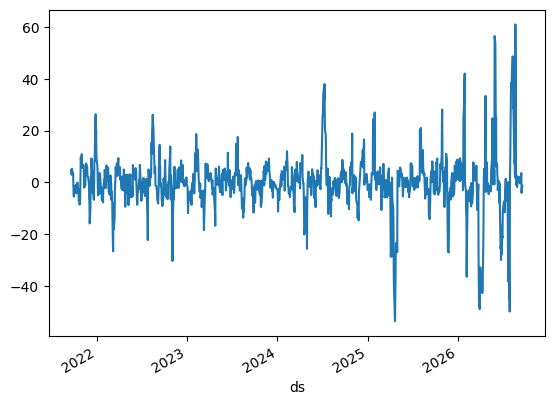

In [35]:
stl = STL(stocks['y'],  period=20, robust=True)
res = stl.fit()

fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

res.resid.plot()

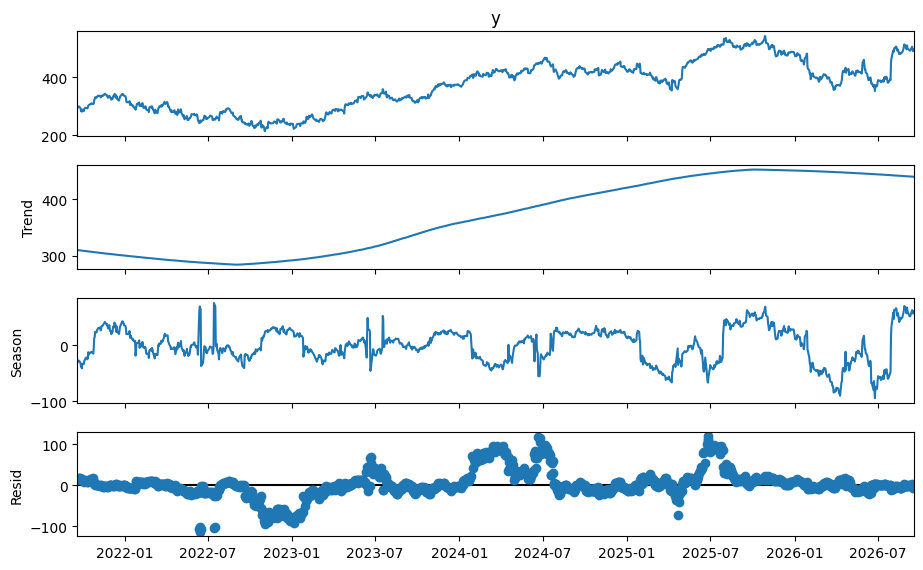

<Axes: xlabel='ds'>

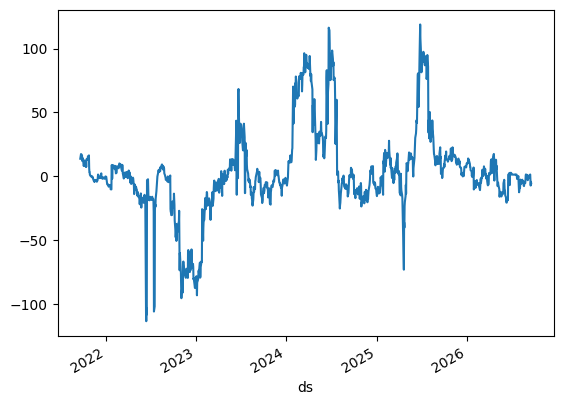

In [36]:
stl = STL(stocks['y'],  period=252, robust=True)
res = stl.fit()

fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

res.resid.plot()

🌵 **А как обстоят дела с автокорреляцией и стационарностью?**

In [37]:
acorr_ljungbox(res.resid, return_df=True)

,lb_stat,lb_pvalue
1,1172.234264,6.601261e-257
2,2263.663084,0.000000e+00
3,3303.436821,0.000000e+00
4,4310.098244,0.000000e+00
5,5302.295210,0.000000e+00
6,6273.287659,0.000000e+00
7,7211.475402,0.000000e+00
8,8109.445058,0.000000e+00
9,8968.465204,0.000000e+00
10,9790.287877,0.000000e+00


In [38]:
adf_test(res.resid)

Results of Dickey-Fuller Test:
Test Statistic                   -3.660080
p-value                           0.004711
#Lags Used                       22.000000
Number of Observations Used    1232.000000
Critical Value (1%)              -3.435669
Critical Value (5%)              -2.863889
Critical Value (10%)             -2.568021
dtype: float64


/tmp/ipykernel_22950/4074047635.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



Остатки снова получились стационарными и автокоррелированными.



🌵 **В чём может быть проблема?**

### Декомпозиция MSTL

**MSTL** (Multiple Seasonal and Trend Decomposition using LOESS) — расширение STL для нескольких сезонностей.

Метод по очереди выделяет сезонные компоненты заданных периодов с помощью STL, учитывая уже оценённые компоненты. Процедура повторяется, уточняя разложение. Затем получаем тренд, сезонные компоненты и остаток.

Например, у почасовых заказов доставки могут одновременно присутствовать суточный и недельный циклы: периоды 24 и 168. MSTL не ищет эти периоды автоматически — их задаём мы.

*Подходит для*

* Рядов с несколькими обоснованными сезонными паттернами.

В нашем ряду нет выходных и биржевых праздников. Как и выше, рассматриваем приближённые периоды:

* 5 торговых сессий — примерно неделя;
* 20 — примерно месяц;
* 252 — примерно год.

Теперь включим их в MSTL одновременно. Сравнение со STL с периодом 252 показывает результат добавления двух компонент, но само по себе не доказывает превосходство MSTL или наличие всех трёх сезонностей у цен акций.

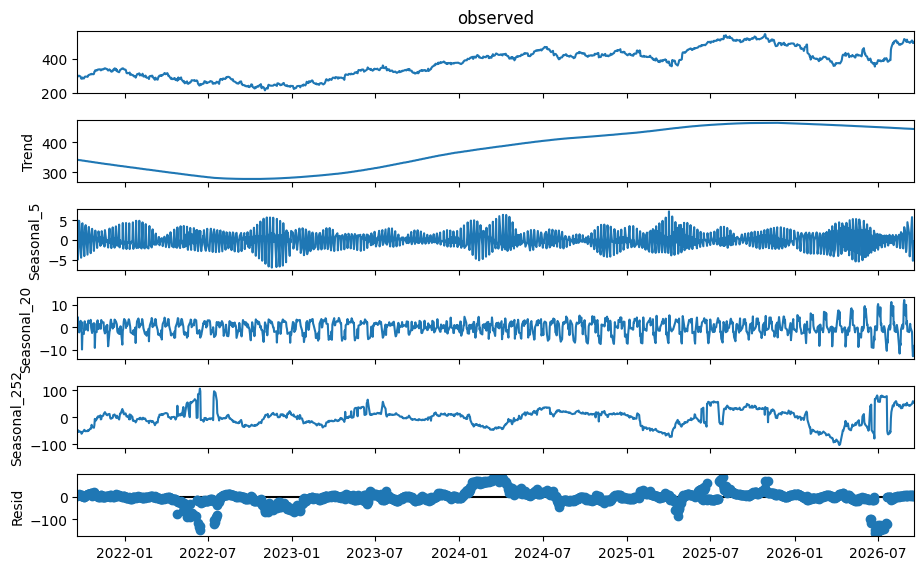

<Axes: xlabel='ds'>

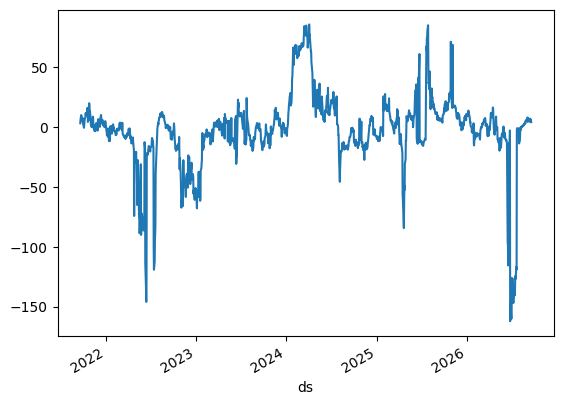

In [39]:
mstl = MSTL(stocks['y'],  periods=(5, 20, 252), stl_kwargs={'robust': True})
res = mstl.fit()

fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

res.resid.plot()

🌵 **Как здесь обстоят дела с автокорреляцией и стационарностью?**

In [40]:
acorr_ljungbox(res.resid, return_df=True)

,lb_stat,lb_pvalue
1,1089.289348,7.027392e-239
2,2046.883308,0.000000e+00
3,2875.278901,0.000000e+00
4,3618.130068,0.000000e+00
5,4335.462176,0.000000e+00
6,5016.470170,0.000000e+00
7,5682.443786,0.000000e+00
8,6292.630773,0.000000e+00
9,6848.930880,0.000000e+00
10,7352.443610,0.000000e+00


In [41]:
adf_test(res.resid)

Results of Dickey-Fuller Test:
Test Statistic                   -3.751801
p-value                           0.003441
#Lags Used                       19.000000
Number of Observations Used    1235.000000
Critical Value (1%)              -3.435656
Critical Value (5%)              -2.863883
Critical Value (10%)             -2.568018
dtype: float64


/tmp/ipykernel_22950/4074047635.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



Если остатки стационарны, но автокоррелированы, оставшуюся динамику можно моделировать отдельно — декомпозиция не обязана сразу давать белый шум.


Что делать, **если остатки автокоррелированы?**

* Посмотрите, на каких лагах заметна зависимость. Проверьте, обоснованы ли выбранные сезонные периоды предметной областью и данными.
* Если остатки стационарны, попробуйте описать их динамику моделью ARMA. Если нет — сначала разберитесь с причиной нестационарности.
* Рассмотрите внешние факторы, доступные на момент прогноза.
* При выборе прогнозной модели сравнивайте итоговые прогнозы на отложенных данных. Не подбирайте периоды только ради большого p-value Ljung–Box.

### Как проверить декомпозицию?

1. **Посмотрите на остатки**. Если в них остался заметный рост/спад или повторяющийся сезонный рисунок, разложение стоит пересмотреть. При этом остатки не обязаны быть белым шумом (хотя хорошо бы).
2. **Проверьте параметры декомпозиции**.
   - Тренд не улавливает длительные изменения → уменьшите окно тренда.
   - Тренд повторяет мелкие случайные колебания → увеличьте окно.
   - Осталась сезонная структура → проверьте период и гибкость сезонной компоненты.
   - Выбросы искажают компоненты → попробуйте robust=True.
   Цель — выделить структуру, не подгоняясь под шум.
3. **Проверьте модель**. Если на изначальном ряде сезонные колебания растут вместе с уровнем положительного ряда - попробуйте мультипликативную декомпозицию.
4. Если приемлемых вариантов несколько и цель — прогноз, сравните итоговые прогнозы на нескольких будущих отрезках.

Итог: ищем разложение, после которого в остатках нет явного неучтённого тренда и сезонного рисунка, а компоненты не повторяют шум. Тесты ADF и Ljing-Box помогают диагностировать остатки, но выбирать победителя по величине их p-value не следует.

## Итоги по приведению к стационарности

**Когда применять каждую технику?**

* **Дифференцирование** — для устранения стохастического тренда; сезонные разности — для соответствующей сезонной нестационарности. Результат нужно проверять.
* **Процентный прирост** — для анализа относительных изменений при разных уровнях ряда. Он не гарантирует постоянную волатильность или стационарность.
* **Классическая декомпозиция** — для одной устойчивой сезонности и плавного тренда при отсутствии сильных выбросов.
* **STL** — для одной сезонности с меняющимся рисунком и гибкого сглаживания тренда; `robust=True` уменьшает влияние выбросов.
* **MSTL** — для нескольких сезонностей с обоснованными периодами.

Декомпозиция помогает выделить структуру ряда, но её остаточная компонента не обязана сразу стать стационарной или белым шумом.

# Прогнозирование с ARMA

**Формула ARMA(p,q)**

$y_{t} = \alpha_{0} + \alpha_{1}y_{t-1} + ... + \alpha_{p}y_{t-p} + \beta_{1}\epsilon_{t-1} + ... + \beta_{q}\epsilon_{t-q} + \epsilon_{t}$, где $\epsilon_{t}$ — белый шум.

🌵 **Чего требуют модели ARMA от временных рядов?**

Модели ARMA требуют, чтобы временной ряд был стационарным.

Сделаем ряд акций стационарным с помощью дифференцирования. Помните, мы уже это делали: дифференцирование первого порядка лежит в столбце `diff`.

In [42]:
stocks.head()

,y,diff,y_restored_diff,pct_change,y_restored_pct_change
ds,,,,,
2021-09-20,294.30,NaN,NaN,NaN,NaN
2021-09-21,294.80,0.50,294.80,0.169895,294.80
2021-09-22,298.58,3.78,298.58,1.282225,298.58
2021-09-23,299.56,0.98,299.56,0.328220,299.56
2021-09-24,299.35,-0.21,299.35,-0.070103,299.35


Сохраним разности и уберём `NaN`. **До подбора модели** отложим последние 20 торговых сессий: это будет наш прогнозный горизонт, т.е. test. Все решения о порядках модели принимаем по train; test используем для итоговой оценки.

In [44]:
stocks_diff = stocks[['diff']].dropna().copy()
forecast_size = 20
train_size = len(stocks_diff) - forecast_size
train, test = stocks_diff.iloc[:train_size], stocks_diff.iloc[train_size:]

adf_test(train['diff'])

Results of Dickey-Fuller Test:
Test Statistic                  -34.316594
p-value                           0.000000
#Lags Used                        0.000000
Number of Observations Used    1233.000000
Critical Value (1%)              -3.435665
Critical Value (5%)              -2.863887
Critical Value (10%)             -2.568020
dtype: float64


/tmp/ipykernel_22950/4074047635.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



## Прогноз in-sample

На занятиях 3–4 мы строили только in-sample прогнозы. Сегодня начнем с них же.

Начнём с выбора порядков для модели ARMA(p,q).

🌵 **Как подобрать порядки (p,q) для модели ARMA(p,q)?**

С помощью ACF и PACF:

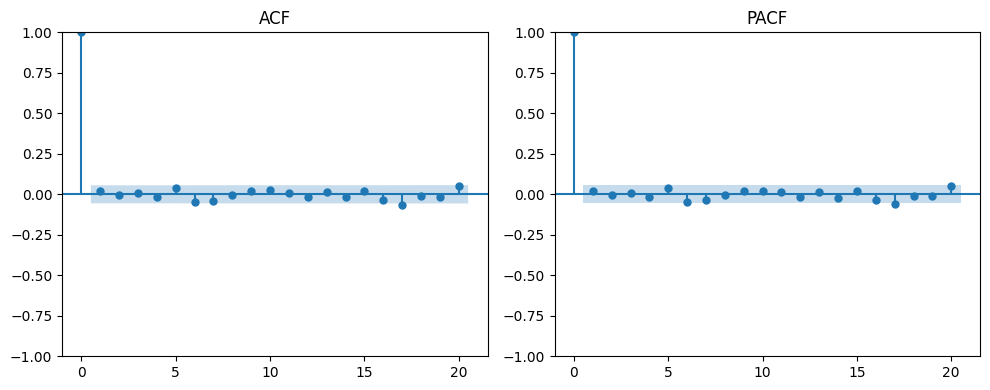

In [45]:
# 2 графика рядом
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# ACF
plot_acf(train, ax=ax[0], lags=20)
ax[0].set_title('ACF')

# PACF
plot_pacf(train, ax=ax[1], lags=20)
ax[1].set_title('PACF')


plt.tight_layout()
plt.show()

С помощью AIC:

In [46]:
best_params = []
for p in range(3):  # p = 0, 1, 2
    for q in range(3):  # q = 0, 1, 2
        candidate = ARIMA(train, order=(p, 0, q)).fit(method_kwargs={'maxiter': 500})
        if not candidate.mle_retvals['converged']:
            print(f'ARMA({p},{q}): нет сходимости, пропускаем сравнение AIC/BIC')
            continue
        best_params.append({'p': p, 'q': q, 'AIC': candidate.aic, 'BIC': candidate.bic})

criteria = pd.DataFrame(best_params).sort_values('AIC')
criteria['delta_AIC'] = criteria['AIC'] - criteria['AIC'].min()
criteria


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been 

,p,q,AIC,BIC,delta_AIC
0,0,0,8068.353537,8078.589570,0.000000
1,0,1,8069.746923,8085.100972,1.393386
3,1,0,8069.754071,8085.108120,1.400534
4,1,1,8070.018836,8090.490900,1.665298
8,2,2,8070.579702,8101.287799,2.226165
2,0,2,8071.702814,8092.174879,3.349276
6,2,0,8071.710514,8092.182579,3.356977
5,1,2,8072.018178,8097.608259,3.664641
7,2,1,8073.709008,8099.299089,5.355471


🌵 **Какие порядки (p,q) подходят лучше всего?**

Сравните не только минимальный AIC, но и разницу между моделями (`delta_AIC`), а также BIC. Маленькая разница AIC — слабый аргумент в пользу усложнения. Полезно отдельно посмотреть на ARMA(0,0): это модель с постоянным средним и белым шумом.

Для разбора AR- и MA-коэффициентов ниже оставим **ARMA(2,2) как заранее заданный учебный пример**. Это не утверждение, что она лучше всех прогнозирует. Её пользу проверим на test в сравнении с простым базовым прогнозом.
Если минимальный AIC оказался у ARMA(0,0), это не ошибка: дополнительные лаги не дали достаточного улучшения с учётом штрафа за сложность. Здесь моделируем **разности цен**, поэтому ARMA(0,0) прогнозирует среднее изменение, а после обратного преобразования цена меняется с постоянным шагом.

In [47]:
# Инициализируем ARMA(2,2)
model = ARIMA(train, order=(2,0,2)) # порядки (p,d,q), p - AR, q - MA

# Фитим модель
model = model.fit(method_kwargs={'maxiter': 500})
print('Сходимость:', model.mle_retvals['converged'])

print(model.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-invertible starting MA paramete

Сходимость: True
                               SARIMAX Results                                
Dep. Variable:                   diff   No. Observations:                 1234
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -4029.290
Date:                Mon, 21 Sep 2026   AIC                           8070.580
Time:                        16:45:12   BIC                           8101.288
Sample:                             0   HQIC                          8082.131
                               - 1234                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1712      0.055      3.139      0.002       0.064       0.278
ar.L1          0.1653      0.176      0.939      0.348      -0.180       0.510
ar.L2          0.8203      0.175   

🌵 **Какие коэффициенты оказались значимыми?**

Сначала посмотрите на строку **«Сходимость»**. `True` означает, что алгоритм сообщил о сходимости; это не гарантия хорошего прогноза. Если получилось `False`, сначала разберитесь с оцениванием: можно увеличить число итераций (maxiter) или попробовать более простую модель (меньшие p и q). До этого не стоит уверенно интерпретировать p-value коэффициентов. Выше мы увеличили лимит до 500 итераций, а при подборе по AIC/BIC исключаем модели без сходимости.

В столбце `P>|z|` проверяется гипотеза, что конкретный коэффициент равен нулю при наличии остальных параметров. При p-value < 0.05 называем его статистически значимым на уровне 5%.

**Что делать, если некоторые коэффициенты незначимы?** Модель, возможно, избыточно сложная. Попробуем несколько более простых спецификаций, заново оценим все их параметры и сравним модели по AIC/AICc/BIC, остаткам и качеству прогноза на временной валидации внутри train. Test оставим для итоговой оценки. Добиваться значимости каждого коэффициента любой ценой не нужно: незначимость не доказывает, что коэффициент равен нулю или модель бесполезна.

Просто повторить `.fit()` с теми же настройками недостаточно. И нельзя механически уменьшать порядок из-за любого незначимого лага: например, уменьшение `p` с 2 до 1 убирает **второй**, а не первый AR-лаг. Эти же правила применимы к ARIMA ниже.


Теперь спрогнозируем $\hat{y_t}$ (будем называть `y_hat`) для нашего ряда $y_t$.

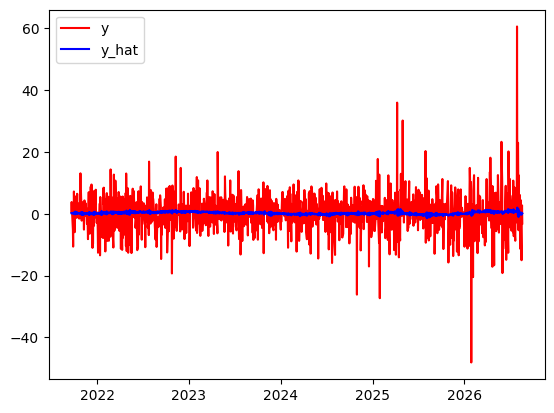

In [48]:
forecast = model.predict()

plt.plot(train,color='red')
plt.plot(forecast,color='blue')
plt.legend(['y','y_hat'])
plt.show()

Далее давайте обсудим: как модель ARMA на самом деле оценивает коэффициенты $\alpha$ и $\beta$?

### Оценка максимального правдоподобия (MLE)


Простой пример (по [Демешеву](https://www.youtube.com/watch?v=2iRIqkm1mug)):

Представьте, что вы пришли на площадь **вечером в случайно выбранный день невисокосного года** и увидели работающий фонтан. Возможны две гипотезы:

1. Фонтан работает каждый вечер.
2. Фонтан работает только один вечер в году.

Вероятность увидеть работающий фонтан в этих случаях:

1. 1;
2. 1/365.

По принципу максимального правдоподобия выбираем первую гипотезу: при ней наблюдаемый результат вероятнее. Мы сравнили вероятность наблюдения при каждой гипотезе, а не вычислили вероятность самих гипотез.

Метод **максимального правдоподобия (MLE)** часто используется для оценки параметров ARMA. Идея такая:

1. Порядки $p$ и $q$ заданы, а коэффициенты модели и дисперсия ошибок неизвестны.
2. Для каждого набора параметров модель задаёт распределение наблюдений.
3. Выбираем параметры, при которых наблюдённые данные имеют наибольшее правдоподобие.

Для непрерывных данных правдоподобие строится из плотностей: вероятность получить в точности заданный набор чисел равна нулю. Пример с фонтаном иллюстрирует ту же идею на дискретном событии.

* Обозначим все параметры модели через $\vartheta$: константу (если она оценивается), AR-коэффициенты $\alpha_1,\ldots,\alpha_p$, MA-коэффициенты $\beta_1,\ldots,\beta_q$ и дисперсию ошибок $\sigma^2$.

* Для наблюдений $y_1,\ldots,y_n$ функцию правдоподобия можно записать через условные плотности:

$$L(\vartheta)=f(y_1;\vartheta)\prod_{t=2}^{n}f(y_t\mid y_1,\ldots,y_{t-1};\vartheta).$$

* Здесь $f$ — плотность, а условие после вертикальной черты означает, что учитывается история ряда. Это позволяет учесть зависимость наблюдений во времени.

* На практике максимизируют логарифм правдоподобия: произведение превращается в сумму.

* Численные методы оптимизации, например BFGS, уточняют параметры, чтобы увеличить лог-правдоподобие.

Когда вы обучаете модель ARMA в библиотеках вроде statsmodels, внутри используется MLE для оценки параметров. Поэтому процесс сводится к указанию порядков (p, q) и вызову `.fit()`: библиотека считает правдоподобие данных при выбранной модели и подбирает параметры.

### Критерии AIC, AICc, BIC

Помните, мы говорили, что AIC и BIC помогают выбрать модель, которая хорошо описывает данные и не содержит лишней сложности.

Эти критерии основаны на концепции правдоподобия.

Обозначим через $K$ **общее число оцениваемых параметров**, а через $L$ — максимизированное правдоподобие.

**AIC (информационный критерий Акаике)**

$$AIC=-2\ln L+2K.$$

У обычной ARMA(p,q) без внешних признаков $K=p+q+2$, если оцениваются константа и дисперсия ошибок; без константы $K=p+q+1$. Константа считается параметром, даже если её оценка близка к нулю или статистически незначима.

**AICc — поправка для небольших выборок**

$$AICc=AIC+\frac{2K(K+1)}{n-K-1},\qquad n>K+1.$$

**BIC (байесовский информационный критерий)**

$$BIC=-2\ln L+K\ln n.$$

При обычных размерах выборки BIC сильнее штрафует сложность, чем AIC. Меньшее значение критерия предпочтительнее **среди сравниваемых моделей**, оценённых на одних наблюдениях при сопоставимом расчёте правдоподобия. В этой лекции сначала выбираем $d$, затем сравниваем разные $p,q$.

Низкий AIC или BIC не заменяет проверки прогноза на новых данных.

Как посчитать AICc?

In [49]:
aic = model.aic
K = len(model.params)  # все оцениваемые параметры
n = model.nobs  # число наблюдений, использованных моделью
aicc = aic + 2 * K * (K + 1) / (n - K - 1)
bic = model.bic

aic, aicc, bic

(np.float64(8070.579702259014),
 np.float64(8070.648161916716),
 np.float64(8101.287799485806))

Эти информационные критерии обычно хорошо помогают выбрать подходящие p и q.

### Остатки модели

**Формула**

$e_t = y_t - \hat{y_t}$

«Остатки» в модели временного ряда — это то, что остаётся после фита модели. Для многих (но не всех) моделей остатки равны разнице между наблюдениями и соответствующими предсказанными значениями.


Хорошая модель прогнозирования даёт остатки со следующими свойствами:

* **Нет автокорреляции**. Если остатки коррелируют, значит, в них осталась полезная информация, которую стоило учесть в модели.
* **Среднее остатка равно нулю**. Иначе прогнозы смещены.

**Любой метод прогнозирования, не удовлетворяющий этим свойствам, можно улучшить. Но даже если метод удовлетворяет этим свойствам, это не значит, что его нельзя сделать лучше.** Для одного и того же набора данных может существовать несколько моделей, отвечающих этим критериям. Проверка свойств нужна, чтобы убедиться, что метод использует всю доступную информацию, но это не лучший способ выбора прогнозной модели.

Теперь проверим остатки.

In [50]:
forecast = pd.DataFrame(forecast)
forecast.columns = ['diff']
forecast

,diff
ds,
2021-09-21,0.171194
2021-09-22,0.177578
2021-09-23,0.235105
2021-09-24,0.104987
2021-09-27,0.185814
...,...
2026-08-14,0.425893
2026-08-17,-0.324186
2026-08-18,0.094588


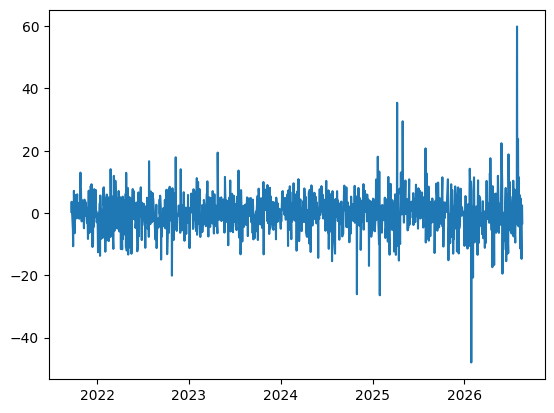

In [51]:
residuals = train - forecast

plt.plot(residuals)

Проверим среднее:

In [52]:
residuals.mean()

,0
diff,-0.045001


Проверим автокорреляцию через тест Ljung-Box.


In [53]:
acorr_ljungbox(residuals, lags=20, model_df=2+2, return_df=True)


,lb_stat,lb_pvalue
1,0.006075,NaN
2,0.366750,NaN
3,0.386290,NaN
4,0.390922,NaN
5,1.567905,0.210511
6,2.963511,0.227238
7,5.310739,0.150407
8,5.372167,0.251197
9,5.819949,0.324135
10,7.201634,0.302602


🌵 **Остатки кажутся хорошими? Что тогда можно сказать о модели?**

Текущие проверки относятся к train (in-sample прогнозу); качество будущего прогноза оценим отдельно на test (out-of-sample прогнозе).

**Зачем в Ljung-Box тесте бывает нужна поправка `p + q`?**

Если проверяем остатки обученной ARMA/ARIMA, часть зависимостей уже учтена при подборе коэффициентов на этих же данных. Поэтому задаём `model_df=p+q`: число степеней свободы для расчёта p-value становится $m-(p+q)$, где $m$ — максимальный проверяемый лаг.

Например, для ARMA(2,2) при $m=10$ получаем $10-4=6$. Проверяем по-прежнему **все лаги с 1-го по 10-й**: поправка меняет p-value, а не набор лагов или саму статистику теста. При $m \le p+q$ вместо p-value будет `NaN`.

## Прогноз out-of-sample

Наконец, перейдём к прогнозу out-of-sample.

Out-of-sample прогнозирование в ARMA означает предсказания на части данных, которая не использовалась при обучении. Это ключевой шаг, чтобы оценить, насколько модель обобщается на новые данные: мы смотрим, как хорошо ARMA предсказывает будущее, опираясь на прошлое, и проверяем результат на отложенной части выборки.

In [54]:
# Train и test уже выделены до подбора модели
train.tail(), test.head()

(             diff
 ds               
 2026-08-14  -1.48
 2026-08-17 -15.05
 2026-08-18   1.28
 2026-08-19   2.68
 2026-08-20  -3.16,
             diff
 ds              
 2026-08-21  2.09
 2026-08-24  4.07
 2026-08-25  4.40
 2026-08-26  4.66
 2026-08-27  8.69)

In [55]:
fig = px.line(title="Microsoft closing prices (daily) - diff(1)")
fig.add_scatter(x=train.index, y=train['diff'], mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=test.index, y=test['diff'], mode='lines', name='test', line=dict(color='green'))

fig.update_layout(template='plotly_white', width=1000, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Теперь обучим новую модель на train и построим прогноз с ARMA(2,2).

In [56]:
# Инициируем ARMA(2,2)
model = ARIMA(train, order=(2,0,2)) # порядки (p,d,q), p - AR, q - MA

# Фитим модель
model = model.fit(method_kwargs={'maxiter': 500})
print('Сходимость:', model.mle_retvals['converged'])

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-invertible starting MA paramete

Сходимость: True


In [57]:
forecast_size = len(stocks_diff) - train_size

forecast_size

20

In [58]:
y_hat = model.forecast(steps=forecast_size, index=test.index)
y_hat = pd.DataFrame(y_hat)
y_hat['ds'] = test.index # переопределяем индексы для прогнозов
y_hat = y_hat.set_index('ds')
y_hat

,predicted_mean
ds,
2026-08-21,0.077083
2026-08-24,0.219585
2026-08-25,0.101998
2026-08-26,0.199447
2026-08-27,0.119106
2026-08-28,0.185758
2026-08-31,0.130876
2026-09-01,0.176474
2026-09-02,0.138996


In [59]:
fig = px.line(title="Microsoft closing prices (daily) - diff(1)")
fig.add_scatter(x=train.index, y=train['diff'], mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=test.index, y=test['diff'], mode='lines', name='test', line=dict(color='green'))
fig.add_scatter(x=y_hat.index, y=y_hat['predicted_mean'], mode='lines', name='forecast', line=dict(color='red'))


fig.update_layout(template='plotly_white', width=1000, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Out-of-sample прогнозы ARMA-моделей опираются на оценённые параметры, прошлые наблюдения (в нашем случае их 2) и последние оценённые ошибки — остатки (тоже 2).

При построении точечного прогноза будущие ошибки заменяются нулём: в стандартной модели их ожидаемое значение при известной истории равно нулю. Прошлые ошибки заменяются оценёнными остатками, а неизвестные будущие значения ряда в AR-части — уже рассчитанными прогнозами.

Например, для MA(1): $y_t = 100 + \epsilon_t + 0.5\epsilon_{t-1}$. Если последний остаток равен 10, прогноз на следующий шаг составит $100 + 0.5\cdot10 = 105$. Со второго шага прогноз будет равен 100, потому что в формуле останутся только будущие ошибки, которые при прогнозировании заменяются нулём.

При увеличении горизонта точечный прогноз стационарной ARMA-модели без внешних факторов стремится к безусловному среднему ряда. Это нормальное поведение модели: влияние последних наблюдений и ошибок постепенно затухает. При этом сами будущие значения ряда продолжают случайно колебаться вокруг среднего.


Наконец, вернём временной ряд и прогноз к исходной шкале.

In [60]:
y_hat.columns = ['diff']
stocks_forecasted = pd.concat([train, y_hat])
stocks_forecasted.head()

,diff
ds,
2021-09-21,0.50
2021-09-22,3.78
2021-09-23,0.98
2021-09-24,-0.21
2021-09-27,-5.18


In [61]:
y_0 = stocks['y'].iloc[0] # берем первое значение для старта
stocks_forecasted['y_restored'] = np.cumsum(stocks_forecasted['diff'])+y_0
arma_price_forecast = stocks_forecasted['y_restored'].iloc[train_size:].copy()
stocks_forecasted.head()

,diff,y_restored
ds,,
2021-09-21,0.50,294.80
2021-09-22,3.78,298.58
2021-09-23,0.98,299.56
2021-09-24,-0.21,299.35
2021-09-27,-5.18,294.17


In [62]:
fig = px.line(title="Microsoft closing prices (daily) - diff(1)")
fig.add_scatter(x=stocks.index, y=stocks['y'], mode='lines', name='y', line=dict(color='blue'))
fig.add_scatter(x=stocks_forecasted.index[train_size:], y=stocks_forecasted['y_restored'][train_size:], mode='lines', name='y_hat', line=dict(color='red'))


fig.update_layout(template='plotly_white', width=1000, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Задание на 20 минут

🌵

**1. Преобразуйте временной ряд в процентные изменения.**

**2. Подберите подходящие порядки (p, q) для ARMA.**

**3. Постройте прогнозы внутри и за пределами обучающей выборки с помощью ARMA (не забудьте разделить временной ряд на обучающую и тестовую выборки).**

**4. Вернитесь к исходной шкале временного ряда.**

# ARIMA(p,d,q)

Модели ARMA работают только со стационарными рядами, поэтому нам приходится сначала преобразовывать данные (например, дифференцировать), а уже затем строить прогноз.

Но есть модель ARIMA. **ARIMA (AutoRegressive Integrated Moving Average)** — популярная модель прогнозирования, объединяющая три компонента: авторегрессию (AR), дифференцирование (I — интегрирование) и скользящее среднее (MA). Она подходит для **временных рядов, которые можно привести к стационарности дифференцированием**, и прогнозирует будущие значения, используя прошлые наблюдения и ошибки прогнозов.

**Формула**

Обозначим дифференцированный ряд через $z_t = \Delta^d y_t$, где $d$ — порядок дифференцирования. Тогда:

$z_t = \alpha_0 + \alpha_1 z_{t-1} + ... + \alpha_p z_{t-p} + \beta_1\epsilon_{t-1} + ... + \beta_q\epsilon_{t-q} + \epsilon_t$, где $\epsilon_t$ — белый шум.

При $d = 1$: $z_t = y_t - y_{t-1}$. То есть ARIMA описывает разности моделью ARMA, а затем возвращает прогноз к исходной шкале. При $d = 0$ дифференцирования нет и ARIMA совпадает с ARMA.


Продолжим с тем же разделением данных. Необходимость первого дифференцирования проверяли на train. Для сравнения с учебной ARMA(2,2) возьмём ARIMA(2,1,2) с дрейфом: константа в разностях соответствует линейному тренду в уровнях.

In [63]:
stocks = stocks['y']
train_size = len(stocks) - forecast_size
train, test = stocks.iloc[:train_size], stocks.iloc[train_size:]

In [64]:
# Инициируем ARIMA(2,1,2)
model = ARIMA(train, order=(2,1,2), trend='t') # порядки (p,d,q), p - AR, q - MA, d - I

# Фитим модель
model = model.fit(method_kwargs={'maxiter': 500})
print('Сходимость:', model.mle_retvals['converged'])

print(model.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-invertible starting MA paramete

Сходимость: True
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1235
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -4029.291
Date:                Mon, 21 Sep 2026   AIC                           8070.582
Time:                        17:12:37   BIC                           8101.290
Sample:                             0   HQIC                          8082.134
                               - 1235                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.1712      0.055      3.132      0.002       0.064       0.278
ar.L1          0.1653      0.176      0.940      0.347      -0.179       0.510
ar.L2          0.8203      0.175   

## Прогноз in-sample

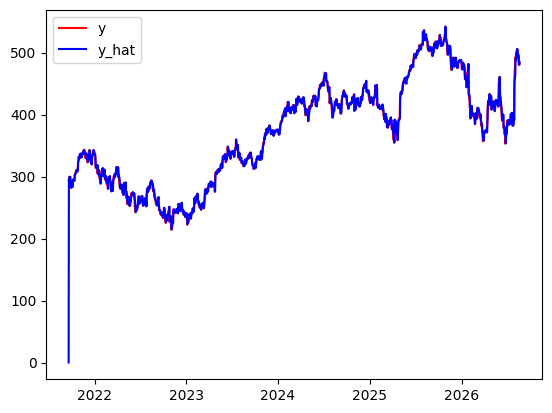

In [65]:
forecast = model.predict()

plt.plot(train,color='red')
plt.plot(forecast,color='blue')
plt.legend(['y','y_hat'])
plt.show()

Приблизим график:

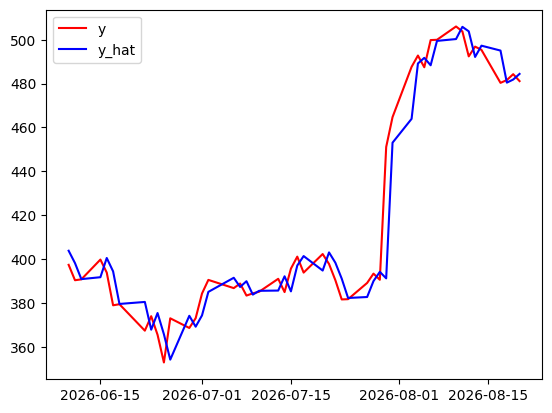

In [66]:
plt.plot(train.iloc[-50:],color='red') # last 50 training observations
plt.plot(forecast[-50:],color='blue')
plt.legend(['y','y_hat'])
plt.show()

## Прогноз out-of-sample

In [67]:
# Используем прежний test: последние 20 торговых сессий.
train.tail(), test.head()

(ds
 2026-08-14    495.40
 2026-08-17    480.35
 2026-08-18    481.63
 2026-08-19    484.31
 2026-08-20    481.15
 Name: y, dtype: float64,
 ds
 2026-08-21    483.24
 2026-08-24    487.31
 2026-08-25    491.71
 2026-08-26    496.37
 2026-08-27    505.06
 Name: y, dtype: float64)

In [68]:
fig = px.line(title="Microsoft closing prices (daily) - diff(1)")
fig.add_scatter(x=train.index, y=train, mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=test.index, y=test, mode='lines', name='test', line=dict(color='green'))

fig.update_layout(template='plotly_white', width=1000, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Обучим модель на train и спрогнозируем с ARIMA(2,1,2).

In [69]:
# Инициируем ARIMA(2,1,2)
# Добавляем тренд - чтобы модель была сопоставима с пред. ARIMA(p,0,q)
model = ARIMA(train, order=(2,1,2), trend='t') # порядки (p,d,q), p - AR, q - MA, d - I

# Fit the model
model = model.fit(method_kwargs={'maxiter': 500})
print('Сходимость:', model.mle_retvals['converged'])

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-invertible starting MA paramete

Сходимость: True


In [70]:
forecast_size = len(test)
forecast_size

20

In [71]:
y_hat = model.get_forecast(steps=forecast_size, index=test.index)
y_hat = y_hat.predicted_mean
y_hat = pd.DataFrame(y_hat)
y_hat['ds'] = test.index # переопределяем индексы для прогнозов
y_hat = y_hat.set_index('ds')
arima_price_forecast = y_hat['predicted_mean'].copy()
y_hat

,predicted_mean
ds,
2026-08-21,481.226851
2026-08-24,481.446445
2026-08-25,481.548251
2026-08-26,481.747677
2026-08-27,481.866619
2026-08-28,482.052333
2026-08-31,482.183066
2026-09-01,482.359482
2026-09-02,482.498349


In [72]:
fig = px.line(title="Microsoft closing prices (daily) - diff(1)")
fig.add_scatter(x=train.index, y=train, mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=test.index, y=test, mode='lines', name='test', line=dict(color='green'))
fig.add_scatter(x=y_hat.index, y=y_hat['predicted_mean'], mode='lines', name='forecast', line=dict(color='red'))


fig.update_layout(template='plotly_white', width=1000, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Обратите внимание: здесь модель вернула **predicted_mean** — ожидаемое будущее значение ряда при известной истории и выбранной модели. Это точечный прогноз, а не гарантия того, что мы увидим именно такую цену.

Математическое ожидание не обязательно совпадает с наиболее вероятным значением; у нормального распределения они совпадают. Чтобы показать неопределённость, вместе с точечным прогнозом можно использовать **прогнозный интервал** — диапазон для будущего наблюдения, рассчитанный при предпосылках модели. Это не доверительный интервал для среднего.

Подробнее: [Hyndman — прогнозные распределения и интервалы](https://otexts.com/fpp3/prediction-intervals.html).


Важно: критерии AIC, AICc и BIC плохо помогают выбирать порядок дифференцирования (d). Дифференцирование меняет данные, по которым считается правдоподобие, поэтому **значения AIC/AICc/BIC у моделей с разными d некорректно сравнивать**. Значит, d выбираем другими методами, а затем используем AIC или BIC для подбора p и q.

Как выбрать $d$? Используем только **train**.

1. Начните с $d=0$: посмотрите на ряд и проверьте единичный корень. Если дифференцирование не требуется, оставьте $d=0$.
2. Если есть основания для разностей, проверьте результат первого дифференцирования ($d=1$).
3. При необходимости рассмотрите второй порядок ($d=2$), но не увеличивайте его автоматически до получения желаемого p-value.
4. Если проблема сохраняется, проверьте сезонность, структурные сдвиги и изменение дисперсии. Эти причины не всегда устраняются обычными разностями.

Обычно достаточно $d=0,1,2$. Лишнее дифференцирование может добавить ненужную динамику и ухудшить прогноз. Затем подбираем $p,q$ на train, а test оставляем для итоговой оценки.

## Auto-ARIMA

**Auto ARIMA (Auto-Regressive Integrated Moving Average)** — автоматизированный алгоритм выбора наилучшей ARIMA-модели для прогнозирования временных рядов. Он упрощает поиск оптимальных параметров p, d, q.

In [73]:
# Фитим модель ARIMA
model = auto_arima(train, stepwise=True, trace=True, maxiter=500, suppress_warnings=False)

# Саммаризация по модели
print('Сходимость:', model.arima_res_.mle_retvals['converged'])
print(model.summary())

# Делаем предсказание
forecast_auto_arima = model.arima_res_.forecast(
    steps=len(test), index=test.index
)
print(forecast_auto_arima)

Performing stepwise search to minimize aic


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning:

Non-invertible starting MA parameters found. Using zeros as starting parameters.



 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=5.16 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8068.354, Time=0.05 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8069.754, Time=0.11 sec


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been 

 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8069.747, Time=0.26 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8067.055, Time=0.04 sec


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.



 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=8070.019, Time=0.88 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 6.523 seconds
Сходимость: True
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1235
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -4032.527
Date:                Mon, 21 Sep 2026   AIC                           8067.055
Time:                        17:22:15   BIC                           8072.173
Sample:                             0   HQIC                          8068.980
                               - 1235                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2        40.3606      0.644     62.706      0

**Как работает Auto-ARIMA?**

В pmdarima `auto_arima` по умолчанию определяет порядок разностей с помощью KPSS и выполняет пошаговый поиск по спецификациям ARIMA с минимизацией **AIC**. Параметры каждой кандидатной модели оцениваются методом максимального правдоподобия.

Для выбора по AICc нужно явно передать `information_criterion='aicc'`. Пошаговый поиск экономит вычисления, но не гарантирует глобально лучшую модель среди всех возможных вариантов.

Все решения принимаются по переданному `train`. Подробнее: [документация pmdarima](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html) и [Hyndman](https://otexts.com/fpp3/arima-r.html).

In [74]:
forecast_auto_arima = pd.DataFrame(forecast_auto_arima)
forecast_auto_arima['ds'] = test.index
forecast_auto_arima.set_index('ds', inplace=True)
forecast_auto_arima.columns = ['y_hat']

forecast_auto_arima

,y_hat
ds,
2026-08-21,481.15
2026-08-24,481.15
2026-08-25,481.15
2026-08-26,481.15
2026-08-27,481.15
2026-08-28,481.15
2026-08-31,481.15
2026-09-01,481.15
2026-09-02,481.15


In [75]:
fig = px.line(title="Microsoft closing prices (daily)")
fig.add_scatter(x=train.index, y=train, mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=test.index, y=test, mode='lines', name='test', line=dict(color='green'))
fig.add_scatter(x=forecast_auto_arima.index, y=forecast_auto_arima['y_hat'], mode='lines', name='forecast', line=dict(color='red'))


fig.update_layout(template='plotly_white', width=800, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()

Auto-ARIMA автоматизирует выбор порядков модели и наличия константы/дрейфа. Она не обладает отдельным механизмом улучшения остатков у той же самой модели: при одинаковых данных, спецификации и найденном оптимуме прогнозы должны быть сопоставимы.


В ручной ARIMA мы указали `trend='t'`: при d=1 это задаёт дрейф, соответствующий константе в модели разностей. Различия в наличии дрейфа сами по себе могут заметно менять долгосрочный прогноз.

Задание на 10 минут

🌵 **Спрогнозируйте тренд цен акций с помощью Auto-ARIMA.**

**1. Выполните MSTL-декомпозицию временного ряда и извлеките тренд — далее вам понадобится только он.**

**2. Постройте прогноз за пределами обучающей выборки с помощью Auto-ARIMA (не забудьте разделить временной ряд на обучающую и тестовую выборки).**

<Axes: xlabel='ds'>

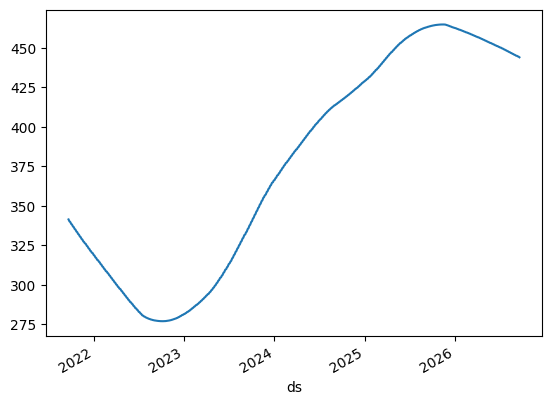

In [76]:
trend = res.trend
trend.plot()

# your code here

# Регрессии

## Простая и множественная линейные регрессии

В простейшем случае **модель простой регрессии** описывает линейную связь между прогнозируемой переменной y и одним предиктором x:

$y_t = \beta_0 + \beta_1*x_t + \epsilon_t$

Здесь $y$ — зависимая переменная, а $x$ — независимая.

**Множественная линейная регрессия** похожа на простую, но использует несколько предикторов, среди которых могут быть лаги ряда или внешние признаки:

$y_t = \beta_0 + \beta_1*x_{1,t} + \beta_2*x_{2,t} + ... + \beta_k*x_{k,t} + \epsilon_t$

Коэффициенты $\beta_1, ..., \beta_k$ показывают вклад каждого предиктора с учётом остальных. То есть они отражают **предельные эффекты**: изменение зависимой переменной при изменении одного предиктора при прочих равных.

### Предпосылки

Используя модель линейной регрессии, мы неявно делаем некоторые предположения о переменных.

1. **Модель достаточно хорошо приближает реальность.** То есть связь между прогнозируемой переменной и предикторами описывается некоторым линейным уравнением.

2. **Ошибки $\epsilon_t$ должны:**

   - Иметь нулевое среднее; иначе прогнозы будут систематически смещены.
   - Не иметь автокорреляции; иначе прогнозы будут неэффективными, поскольку в данных останется информация, которую можно использовать.
   - Не быть связанными с предикторами; иначе в ошибках останется информация, которую следует включить в систематическую часть модели.

3. **Каждый предиктор $x_t$ не является случайной величиной.** В контролируемом лабораторном эксперименте мы могли бы задавать значения каждого $x$ — тогда они не были бы случайными — и наблюдать полученные значения $y$. В наблюдательных данных, включая большинство данных в бизнесе и экономике, мы не можем управлять значениями $x$, а лишь наблюдаем их. Поэтому неслучайность предикторов принимается как предположение.

4. **Остатки модели должны быть стационарными, чтобы избежать фиктивной регрессии.** Если остатки не обладают свойствами стационарности, результаты могут указывать на ложные связи между переменными.

## Предикторы или регрессоры

### Dummy-регрессоры

**Dummy-регрессоры** помогают моделировать связь временного ряда с особыми периодами: праздниками, промоакциями, событиями или изменениями политики. Такой регрессор равен 1 в выбранный период и 0 в остальных наблюдениях.

Для заранее известных календарных событий значения легко задать и в будущем. Для неожиданных событий это не так: нужны отдельные сценарии или прогнозы. Само наличие dummy ещё не доказывает, что событие влияет на ряд.


**Бизнес-пример: конец квартала и ребалансировка портфелей**

Представьте инвестиционный фонд, который пересматривает доли активов к концу квартала. Учебная гипотеза: сделки таких участников могут сопровождаться отличиями в доходности акций в этот период. Проверим, полезен ли признак близости конца квартала для прогноза; заранее наличие эффекта и его знак нам неизвестны.

Создадим `quarter_end_week`:

* **1** — в последние 7 календарных дней марта, июня, сентября и декабря;
* **0** — в остальные дни.

Например, 24–30 июня — единицы, а 23 июня и 1 июля — нули. Это выбранное учебное окно, а не утверждение, что все фонды проводят сделки именно в эти даты. Кварталы здесь календарные, а не финансовые кварталы Microsoft.

В данных оставим только реальные торговые даты. Будущие значения признака известны из календаря: ни цены test, ни последние наблюдения незавершённого квартала для разметки не нужны. Если будем оценивать связь с доходностью, сначала рассчитаем доходности, а не будем сравнивать уровни цен разных лет. Даже значимый коэффициент сам по себе не докажет причинного влияния ребалансировки.


In [77]:
# Используем только даты торговых сессий из нашего ряда.
regressors = pd.DataFrame(index=stocks.index)
regressors.index.name = 'ds'


In [78]:
# Последние 7 календарных дней квартала.
dates = regressors.index
regressors['quarter_end_week'] = (
    dates.month.isin([3, 6, 9, 12]) & (dates.days_in_month - dates.day < 7)
).astype(int)

print(regressors['quarter_end_week'].value_counts().rename('Число наблюдений'))
regressors.loc[regressors['quarter_end_week'] == 1].head(10)


quarter_end_week
0    1160
1      95
Name: Число наблюдений, dtype: int64


,quarter_end_week
ds,
2021-09-24,1
2021-09-27,1
2021-09-28,1
2021-09-29,1
2021-09-30,1
2021-12-27,1
2021-12-28,1
2021-12-29,1
2021-12-30,1


Задание на 5 минут

🌵 **Создайте dummy для первых 7 календарных дней квартала — января, апреля, июля и октября.**

Представьте, что участники рынка направляют новые квартальные поступления на покупку активов. Это ещё одна гипотеза, а не доказанный эффект. Проверьте, что в признаке есть и 0, и 1. Можно ли заранее задать его значения на даты test? Используются ли при этом будущие цены?


### Непрерывные регрессоры

Вернёмся к исходным данным Microsoft, загруженным в начале ноутбука. В них сохранена и цена открытия.

In [79]:
stocks = stocks_raw.copy()

In [80]:
stocks.head()

,date,close,volume,open,high,low
0,09/18/2026,$493.78,"39,622,290",$497.965,$498.65,$491.10
1,09/17/2026,$497.75,"17,841,640",$497.795,$501.47,$493.17
2,09/16/2026,$490.30,"16,670,290",$493.03,$495.97,$487.23
3,09/15/2026,$497.12,"17,794,610",$500.06,$505.90,$495.54
4,09/14/2026,$505.41,"23,091,890",$497.06,$509.95,$495.3416


Давайте возьмём цену открытия акций как непрерывный регрессор.

**Когда такой признак доступен?** Если мы прогнозируем цену закрытия текущего дня **после открытия торгов**, сегодняшняя цена открытия уже известна и её можно использовать.

Но при прогнозе сразу на 20 дней вперёд будущие цены открытия неизвестны. Их нужно отдельно прогнозировать или задавать сценариями; подставлять фактические цены открытия из test в такой прогноз нельзя — это утечка будущей информации.

Ниже пока только посмотрим на оба ряда. При построении модели сначала определим момент прогноза и проверим, какие признаки к этому моменту действительно известны. Подробнее: [Hyndman — прогнозирование с регрессией](https://otexts.com/fpp3/forecasting-regression.html).


In [81]:
stocks = stocks.rename(columns={'date': 'ds', 'close': 'y', 'open': 'x'})
stocks['ds'] = pd.to_datetime(stocks['ds'], format='%m/%d/%Y')
stocks['y'] = stocks['y'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
stocks['x'] = stocks['x'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

stocks = stocks[['ds', 'y', 'x']].sort_values('ds').set_index('ds')

In [82]:
fig = px.line(title="Microsoft closing and open prices (daily)")
fig.add_scatter(x=stocks.index, y=stocks['y'], mode='lines', name='closing price', line=dict(color='blue'))
fig.add_scatter(x=stocks.index, y=stocks['x'], mode='lines', name='open price', line=dict(color='red'))

fig.update_layout(template='plotly_white', width=800, height=500)
fig.update_xaxes(title_text="date")
fig.update_yaxes(title_text="closing price")
fig.show()


# SUM UP

* Обсудили способы приведения к стационарности: дифференцирование, процентный прирост, декомпозиции (классическую, STL, MSTL) и важность стационарности и отсутствия автокорреляции в остатках
* Разобрали MLE и происхождение критериев AIC, BIC
* Рассмотрели прогноз out-of-sample для моделей ARMA, ARIMA и auto-ARIMA
* Обсудили регрессионные модели для временных рядов
* Попробовали dummy и непрерывные регрессоры (предикторы)

Пожалуйста, оставьте отзыв [здесь](https://forms.gle/nm2Ghoes5n59h4ao8), чтобы сделать занятия ещё эффективнее :)